In [72]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
import math
from scipy.interpolate import CubicSpline 
import tol_colors as tc

import tools
import my_plot as mplt

In [73]:
def extract_PS(folder_path):
    """Extract scattering basis transfer function data from files in a folder """
    folder = Path(folder_path) / "FH" / "yn_T_aniso_system" 
    
    file_path = next(folder.glob("power_spectra_ymax15_lmax15_adiabatic.dat.dat"))

    ell = []
    TT = []
    muT = []
    yT = []

    ell = np.loadtxt(file_path, comments='#')[:, 0]
    TT = np.loadtxt(file_path, comments='#')[:, 1]
    muT = np.loadtxt(file_path, comments='#')[:, 4]
    yT = np.loadtxt(file_path, comments='#')[:, 5]

    return np.array(ell), np.array(TT),np.array(yT), np.array(muT)

In [74]:
ell , TT, yT, muT = extract_PS("../Data/Dark-photons/output_dp_PS/outputs-dp1.0_PS/")
_ , TT_1, yT_1, muT_1 = extract_PS("../Data/Dark-photons/output_dp_PS/outputs-dp1.1_PS/")
_ , TT_2, yT_2, muT_2 = extract_PS("../Data/Dark-photons/output_dp_PS/outputs-dp1.2_PS/")
_ , TT_3, yT_3, muT_3 = extract_PS("../Data/Dark-photons/output_dp_PS/outputs-dp1.3_PS/")



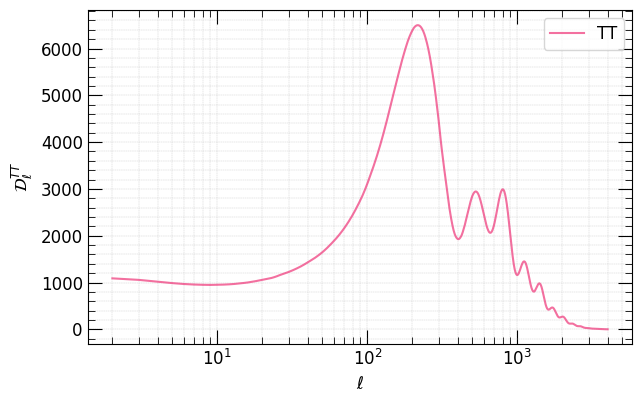

In [75]:
colors = mplt.set_colors(4, palette="colorblind")
colors2 = tc.colorsets['vibrant']

fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))

ax.plot(ell, TT, color=colors2[3], alpha=0.7, linestyle="-", label="TT")


mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=True, y_label="$\\mathcal{D}_\\ell^{{TT}}$", y_log=False, title=None)

plt.savefig('outputs/TT.pdf', dpi=300, bbox_inches="tight")

ax.legend()
plt.show()


The following two plots are for me only, we are not including the first line in the paper. But they nicely show how very early energy injections thermalise immediatly, what we see it is basically only a very small signal due to numerical noise probably

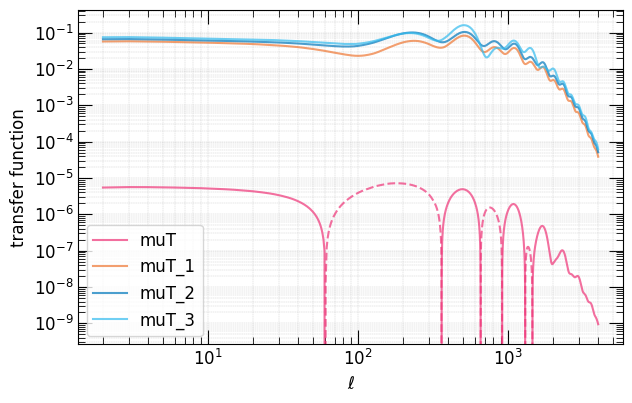

In [76]:

fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))

ax.plot(ell, muT, color=colors2[3], alpha=0.7, linestyle="-", label="muT")
ax.plot(ell, -muT, color=colors2[3], alpha=0.7, linestyle="--")

ax.plot(ell, muT_1, color=colors2[0], alpha=0.7, linestyle="-", label="muT_1")
ax.plot(ell, muT_2, color=colors2[1], alpha=0.7, linestyle="-", label="muT_2")
ax.plot(ell, muT_3, color=colors2[2], alpha=0.7, linestyle="-", label="muT_3")


mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=True, y_label="transfer function", y_log=True, title=None)


ax.legend()
plt.show()

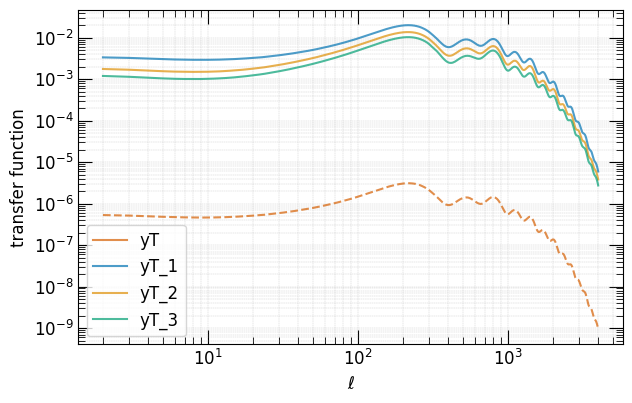

In [77]:

fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))

ax.plot(ell, yT, color=colors[3], alpha=0.7, linestyle="-", label="yT")
ax.plot(ell, -yT, color=colors[3], alpha=0.7, linestyle="--")


ax.plot(ell, yT_1, color=colors[0], alpha=0.7, linestyle="-", label="yT_1")
ax.plot(ell, yT_2, color=colors[1], alpha=0.7, linestyle="-", label="yT_2")
ax.plot(ell, yT_3, color=colors[2], alpha=0.7, linestyle="-", label="yT_3")


mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=True, y_label="transfer function", y_log=True, title=None)


ax.legend()
plt.show()

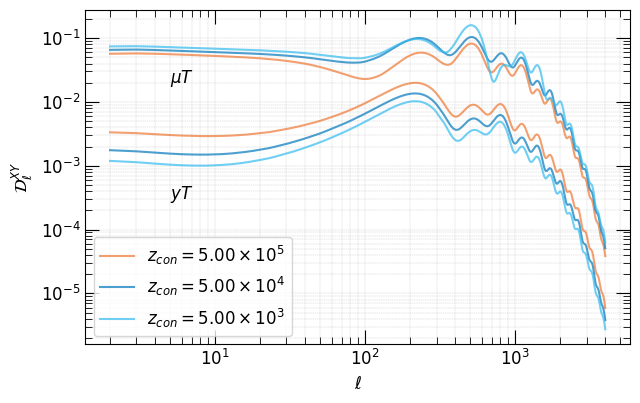

In [78]:
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))



ax.plot(ell, muT_1, color=colors2[0], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e5)}")
ax.plot(ell, muT_2, color=colors2[1], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e4)}")
ax.plot(ell, muT_3, color=colors2[2], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e3)}")

ax.plot(ell, yT_1, color=colors2[0], alpha=0.7, linestyle="-")
ax.plot(ell, yT_2, color=colors2[1], alpha=0.7, linestyle="-")
ax.plot(ell, yT_3, color=colors2[2], alpha=0.7, linestyle="-")


mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=True, y_label="$\\mathcal{D}_{\\ell}^{{XY}} $", y_log=True, title=None)

ax.annotate("$yT$", xy=(5, 3e-4), fontsize=12)
ax.annotate("$\\mu T$", xy=(5, 2e-2), fontsize=12)

plt.savefig('outputs/muT_yT.pdf', dpi=300, bbox_inches="tight")

ax.legend()
plt.show()

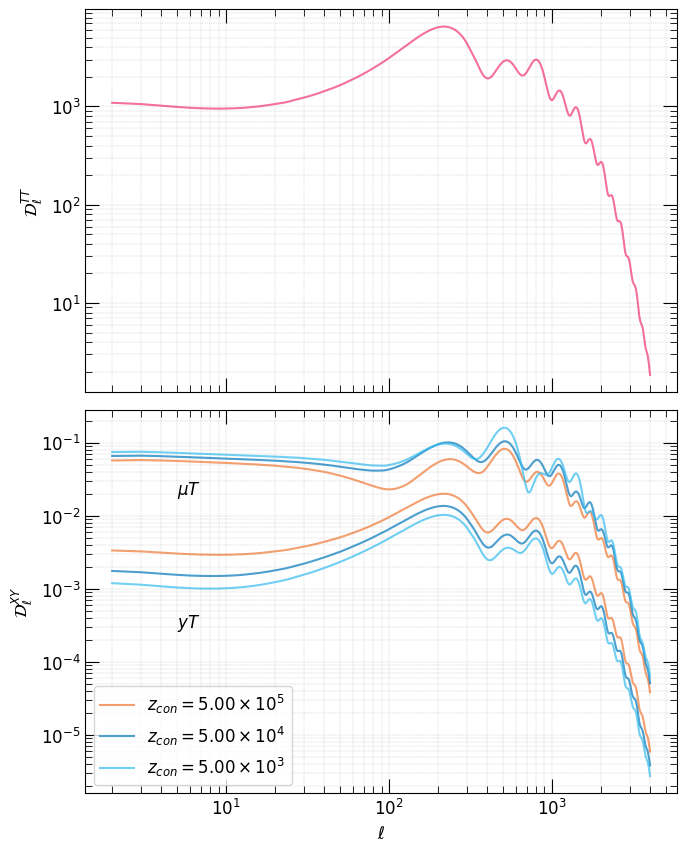

In [85]:
fig, ax = plt.subplots(2, 1, figsize=mplt.set_size(mplt.width, 1, (2,1)), sharex='col')

ax[0].plot(ell, TT, color=colors2[3], alpha=0.7, linestyle="-")


ax[1].plot(ell, muT_1, color=colors2[0], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e5)}")
ax[1].plot(ell, muT_2, color=colors2[1], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e4)}")
ax[1].plot(ell, muT_3, color=colors2[2], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e3)}")

ax[1].plot(ell, yT_1, color=colors2[0], alpha=0.7, linestyle="-")
ax[1].plot(ell, yT_2, color=colors2[1], alpha=0.7, linestyle="-")
ax[1].plot(ell, yT_3, color=colors2[2], alpha=0.7, linestyle="-")


mplt.set_ticks(ax[0])
mplt.set_ticks(ax[1])
ax[0].tick_params(labelbottom=False)
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].set_ylabel("$\\mathcal{D}_\\ell^{{TT}}$")
mplt.set_labels(ax[1], x_label="$\\ell$", x_log=True, y_label="$\\mathcal{D}_{\\ell}^{{XY}} $", y_log=True, title=None)

# ax.annotate("$yT$", xy=(5, 3e-4), fontsize=12)
# ax.annotate("$\\mu T$", xy=(5, 2e-2), fontsize=12)

#plt.savefig('outputs/muT_yT_TT.pdf', dpi=300, bbox_inches="tight")
ax[1].annotate("$yT$", xy=(5, 3e-4), fontsize=12)
ax[1].annotate("$\\mu T$", xy=(5, 2e-2), fontsize=12)
# ax[0].set_ylim(10, 1e4)

plt.tight_layout() 
ax[1].legend()
plt.show()

In [80]:
def extract_PS_batch(folder_path, index_max):
    """Extract scattering basis transfer function data from files in a folder """
    folder = Path(folder_path) / "batch" / "FH" / "yn_T_aniso_system" 

    ellT = []
    TT = []
    muT = []
    yT = []

    
    for i in range(index_max):
        file_path = next(folder.glob(f"power_spectra_ymax15_lmax15_adiabatic_zcon_{i+1:03d}.dat.dat"))

        if i == 0:
            ellT.append(np.loadtxt(file_path, comments='#')[:, 0])

        TT.append(np.loadtxt(file_path, comments='#')[:, 1])
        muT.append(np.loadtxt(file_path, comments='#')[:, 4])
        yT.append(np.loadtxt(file_path, comments='#')[:, 5])

    return np.array(ellT), np.array(TT),np.array(yT), np.array(muT)


In [81]:
ell_batch , TT_batch , yT_batch, muT_batch= extract_PS_batch("../Data/Dark-photons/outputs-dp_PSbatch/",15)

In [82]:
def truncated_cmap(cmap_name, minval=0.1, maxval=0.9, n=15):
    cmap = plt.matplotlib.colormaps[cmap_name]
    return lambda i: cmap(minval + (maxval - minval) * i / (n - 1))

# colors = truncated_cmap("plasma", 0, 0.9, 15)  # vibrant rainbow

colors = tc.rainbow_discrete(15)
#colors = tc.sunset_discrete.resampled(15)

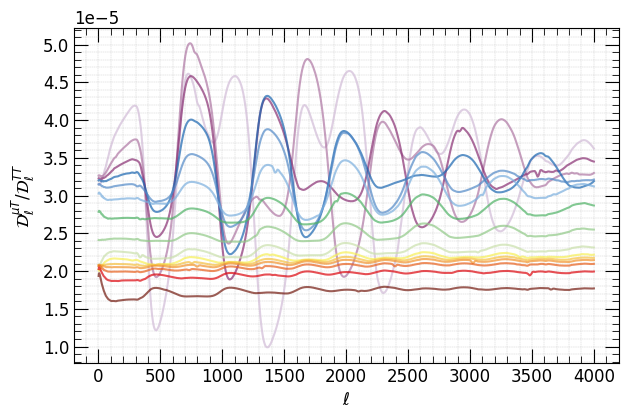

In [83]:
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))




for i in range(len(TT_batch)):
    ax.plot(ell_batch[0], muT_batch[i]/TT_batch[i], color=colors(i), alpha=0.7, linestyle="-", label=f"muT, zcon={tools.sci_notation(5e5/(10**i))}")
    #ax.plot(ell[0], yT[i], color=colors(i), alpha=0.7, linestyle="-.", label=f"yT, zcon={tools.sci_notation(5e5/(10**i))}")

mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=False, y_label="$\\mathcal{D}_{\\ell}^{{\\mu T}} / \\mathcal{D}_{\\ell}^{{TT}}$", y_log=False, title=None)


# ax.annotate("$yT$", xy=(5, 3e-4), fontsize=12)
# ax.annotate("$\\mu T$", xy=(5, 2e-2), fontsize=12)

#plt.savefig('outputs/muT.pdf', dpi=300, bbox_inches="tight")


#ax.legend(fontsize=10)
plt.show()

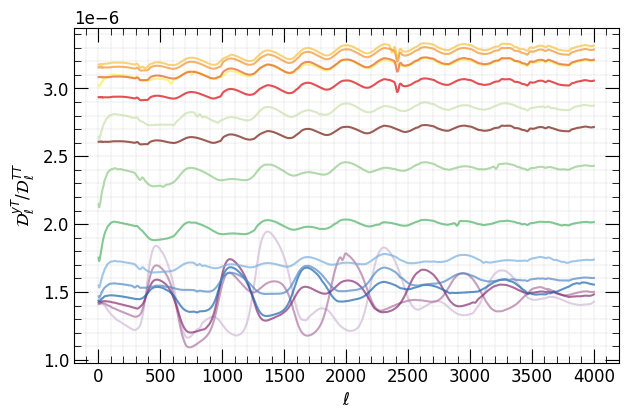

In [84]:
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))


for i in range(len(TT_batch)):
    ax.plot(ell_batch[0], yT_batch[i]/TT_batch[i], color=colors(i), alpha=0.7, linestyle="-", label=f"yT, zcon={tools.sci_notation(5e5/(10**i))}")
    #ax.plot(ell_batch[0], yT_batch[i], color=colors(i), alpha=0.7, linestyle="-.", label=f"yT, zcon={tools.sci_notation(5e5/(10**i))}")

mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=False, y_label="$\\mathcal{D}_{\\ell}^{{y T}} / \\mathcal{D}_{\\ell}^{{TT}}$", y_log=False, title=None)

# ax.annotate("$yT$", xy=(5, 3e-4), fontsize=12)
# ax.annotate("$\\mu T$", xy=(5, 2e-2), fontsize=12)

#plt.savefig('outputs/yT.pdf', dpi=300, bbox_inches="tight")

#ax.legend(fontsize=10)
plt.show()